# Holos-Quad RL Controller Validation Tutorial Notebook

Start by importing local scripts and veery

In [1]:
from veery.mcts import run_MCTS
from veery.fuzzing import DisturbanceDistribution
from veery.naive import *
from veery.viz import *
import profiles
import env
from helpers import load_trained_model
import disturbances
import json

## Setting up the environment profile and disturbance models

First, let's get the testing profile we need to run a pre-trained model in the environment. 

In [2]:
_, testing_kwargs = profiles.get_profile(name="test", max_failed_drums=0)

Next, we need to load the model. 

In [3]:
exp_model = load_trained_model("exp__seed14")

Set up the disturbance distribution to sample noisy readings from.

In [4]:
D = DisturbanceDistribution(
    Do=disturbances.Do(
        sigma_p=0.005, # std of power noise distribution (Gaussian)
        sigma_drum=0.005 # std of drum angle noise distribution (Gaussian)
        ), 
    Da=disturbances.Da(sigma_dtheta=0), # std of rate of change of angle noise distribution (Gaussian)
    Ds=disturbances.Ds(
            sigma_nr=0, # std of neutron density noise distribution (Gaussian)
            sigma_precursors=0, # std of precursor noise distribution (Gaussian)
            sigma_Tf=0, # std of fuel temperature noise distribution (Gaussian)
            sigma_Tm=0, # std of moderator temp noise distribution (Gaussian)
            sigma_Tc=0, # std of coolant temp noise distribution (Gaussian)
            sigma_xe=0, # std of xenon concentration noise distribution (Gaussian)
            sigma_i=0 # std of iodine concentration noise distribution (Gaussian)
            ),
    seed=10)

Now, we can sample from D, the disturbance distribution we defined for this problem. Let's see what a sample from the observation disturbance looks like.

In [5]:
x = D.sample()
print(f"Observation disturbance: {x.xo}")

Observation disturbance: {'p': np.float64(-0.00551669224532766), 'drum_angles': array([-0.00362512, -0.00390903,  0.00133488, -0.0012429 ,  0.00063242,
        0.00421521,  0.00428968,  0.00237592])}


One sample isn't super useful. Let's grab a bunch and check the distribution matches what we expected.

Here's power:

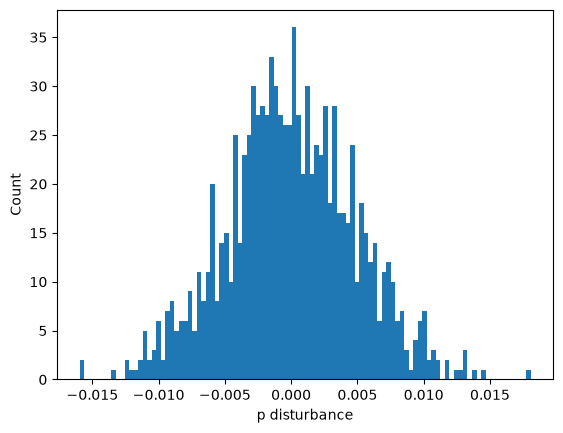

In [6]:
D.plot_samples(dist_type=D.Do, variable="p")

And here's a combined histogram for all the drum angles:

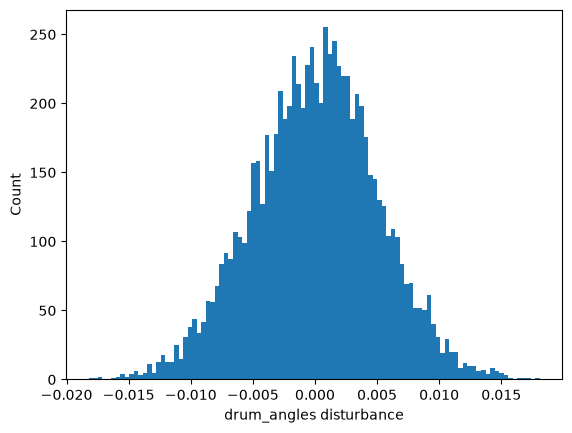

In [7]:
D.plot_samples(dist_type=D.Do, variable="drum_angles")

## Finding failures: Naive Monte Carlo Sampling

In [8]:
environment = env.HolosMulti(**testing_kwargs)
thresh = 0.03

Take 2 with new model

100%|██████████| 100/100 [00:24<00:00,  4.16it/s]


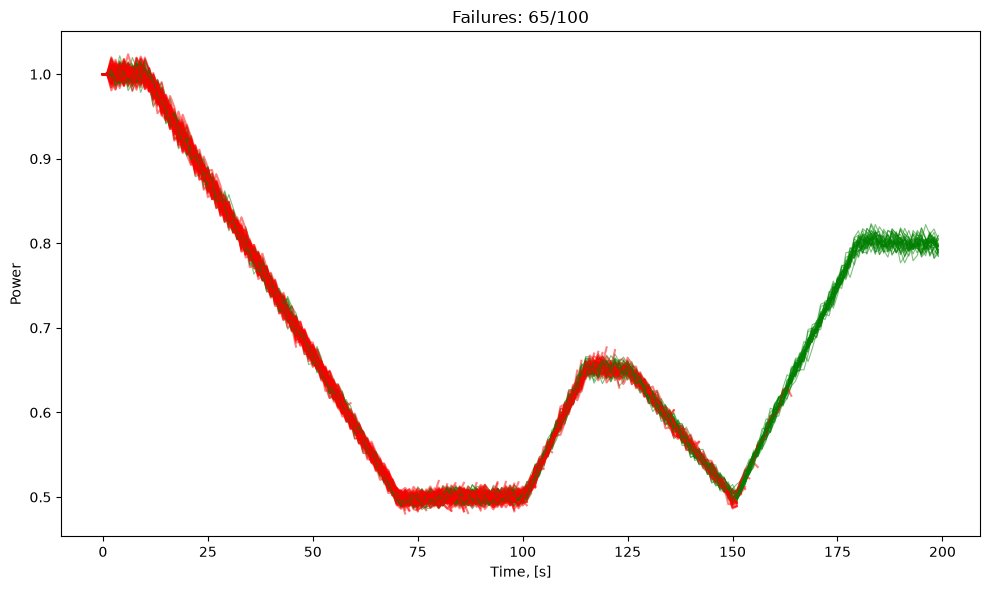

In [9]:
direct_results = direct_falsify(
                environment=environment,
                model=exp_model,
                disturbance_dist=D,
                m = 100,
                threshold = thresh,
                percent = True,
                get_history= lambda e: e.render(),
            )
results, histories  = direct_results["passed"], direct_results["histories"]
plot_rollouts(histories, results, save_dir="results/figs", ylabel="Power");

In [10]:
cost = direct_results["cost"]
print(cost)

{'env_steps': 14174, 'rollouts': 100, 'wall_time_s': 24.05988116699882, 'n_failures': 65, 'first_failure_steps': 102}


## Finding failures: Monte Carlo Tree Search

Now, we run the Monte Carlo Tree Search, from `veery`.

In [ ]:
thresh = 0.03
environment = env.HolosMulti(**testing_kwargs)
tree = run_MCTS(
        environment=environment, 
        model=exp_model,
        disturbance_dist=D, 
        results_path="results/notebook",
        threshold=thresh,
        iterations=100, 
        hyperparams=None
        )

 96%|█████████▌| 96/100 [01:29<00:03,  1.05it/s]

In [ ]:
with open("results/notebook/cost.json") as f:
    mcts_cost = json.load(f)
for key, value in mcts_cost.items():
    print(f"{key}: {value}")

Now, plot the results!

(<Figure size 1000x1600 with 2 Axes>, <Axes: xlabel='Time, [s]'>)

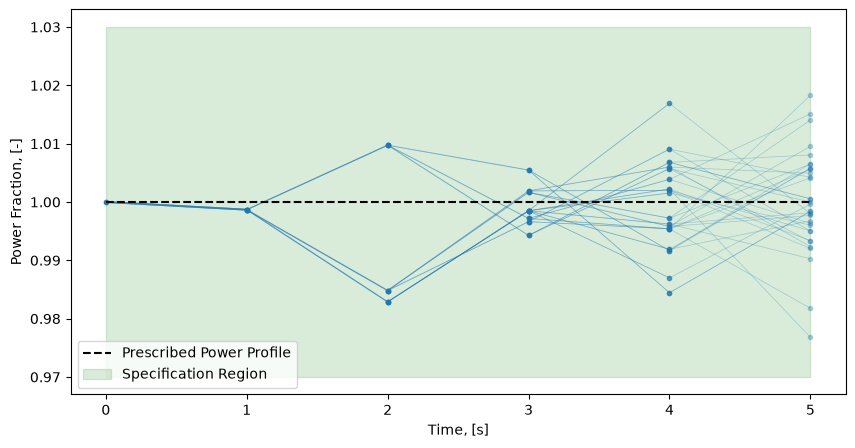

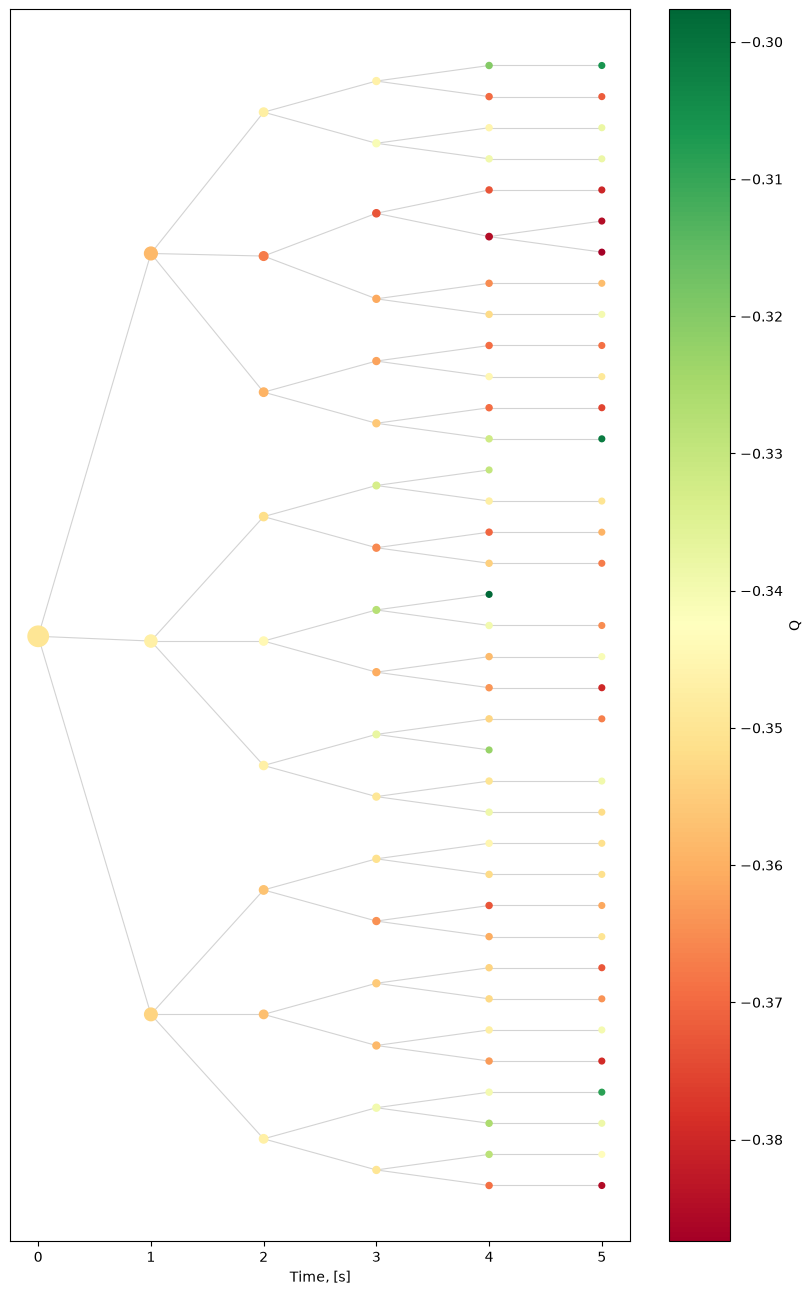

In [ ]:
plot_tree(
        tree,
        spec_var="_p",
        profile=environment.profile,
        threshold=thresh,
        ylabel="Power Fraction, [-]",
        profile_label="Prescribed Power Profile",
        save_path="results/notebook/tree.png",
    )
plot_tree_structure(
        tree, save_path=f"results/notebook/tree_structure.png"
    )